# TA Session 7 — Matching
**Econometrics · Barcelona School of Economics** · Lucia Sauer (lucia.sauer@bse.eu)

Contents
1. **Job training (NSW + CPS)**: can matching recover an experimental estimate? (Python version of `TA7.do`)
   1. Experimental benchmark and naive comparison
   2. Balance before matching
   3. Propensity score and common support
   4. Nearest-neighbour and kernel matching (bootstrap SE)
   5. Balance after matching

Data: `nsw_cps.dta`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

# Course style if available (theme/bse_style.py); otherwise plain matplotlib
try:
    import sys; sys.path.insert(0, "../theme")
    import bse_style; bse_style.apply()
    T_COL, C_COL, PURPLE = bse_style.ORANGE, bse_style.TEAL, bse_style.PURPLE
except ImportError:
    T_COL, C_COL, PURPLE = "tab:orange", "tab:blue", "purple"
GRAY = "#9A9A9A"

## 1. Job training: NSW trainees vs CPS adults

The **National Supported Work** (NSW) program was a randomized job-training experiment in the 1970s. Comparing trainees with the *randomized* controls gives the experimental effect on 1978 earnings: our **benchmark**.

LaLonde (1986) replaced the experimental controls with adults from a survey (the **CPS**), as a researcher without an experiment would, and asked whether non-experimental methods recover the benchmark. Dehejia & Wahba (1999) tried **propensity-score matching**.

`sample`: 1 = NSW trainee, 2 = NSW randomized control, 3 = CPS adult.

In [2]:
nsw = pd.read_stata("nsw_cps.dta")
nsw[["age", "educ"]] = nsw[["age", "educ"]].astype(float)      # stored as int16: age**3 would overflow
print(nsw["sample"].value_counts().sort_index())
nsw.head()

sample
1      185
2      260
3    15992
Name: count, dtype: int64


,treat,age,educ,black,hisp,married,nodegree,re74,re75,re78,sample
0,1,37.0,11.0,1,0,1,1,0.0,0.0,9930.05,1
1,1,22.0,9.0,0,1,0,1,0.0,0.0,3595.89,1
2,1,30.0,12.0,1,0,0,0,0.0,0.0,24909.45,1
3,1,27.0,11.0,1,0,0,1,0.0,0.0,7506.15,1
4,1,33.0,8.0,1,0,0,1,0.0,0.0,289.79,1


### 1.1 Experimental benchmark vs naive comparison

In [3]:
exp_ = smf.ols("re78 ~ treat", nsw[nsw["sample"] <= 2]).fit(cov_type="HC1")
obs = nsw[nsw["sample"] != 2].copy()          # drop the experimental controls: NSW trainees vs CPS
naive = smf.ols("re78 ~ treat", obs).fit(cov_type="HC1")

# Covariates (Dehejia & Wahba 1999)
obs["agesq"] = obs.age ** 2
obs["educsq"] = obs.educ ** 2
obs["u74"] = (obs.re74 == 0).astype(int)       # zero earnings in 1974
obs["u75"] = (obs.re75 == 0).astype(int)
X = ["age", "agesq", "educ", "educsq", "married", "nodegree", "black", "hisp", "re74", "re75", "u74", "u75"]
ols = smf.ols("re78 ~ treat + " + " + ".join(X), obs).fit(cov_type="HC1")

for lab, m in [("Experiment (NSW vs NSW controls)", exp_), ("Naive (NSW vs CPS)", naive), ("OLS + X (NSW vs CPS)", ols)]:
    print(f"{lab:35s} {m.params.treat:9.1f}   (se {m.bse.treat:6.1f})")

Experiment (NSW vs NSW controls)       1794.3   (se  670.8)
Naive (NSW vs CPS)                    -8497.5   (se  581.9)
OLS + X (NSW vs CPS)                   1183.8   (se  627.6)


The experiment says training **raises** 1978 earnings by about \$1,794. The naive comparison with CPS adults says it **lowers** them by \$8,498: CPS adults would earn much more than trainees even without training (selection bias).

### 1.2 Balance before matching
Standardized mean difference: $\text{SMD}_k = (\bar X_{k,1} - \bar X_{k,0}) / \sqrt{(s^2_{k,1} + s^2_{k,0})/2}$. As a rule of thumb, |SMD| < 0.1 is fine.

In [4]:
def smd(x1, x0, w0=None):
    m0 = np.average(x0, weights=w0)
    return (x1.mean() - m0) / np.sqrt((x1.var() + x0.var()) / 2)

t_, c_ = obs[obs.treat == 1], obs[obs.treat == 0]
bal = pd.DataFrame({"Treated": t_[X].mean(), "CPS": c_[X].mean(),
                    "SMD": [smd(t_[v], c_[v]) for v in X]}).round(2)
bal

,Treated,CPS,SMD
age,25.82,33.23,-0.80
agesq,717.39,1225.91,-0.80
educ,10.35,12.03,-0.68
educsq,111.06,152.90,-0.76
married,0.19,0.71,-1.23
nodegree,0.71,0.30,0.90
black,0.84,0.07,2.43
hisp,0.06,0.07,-0.05
re74,2095.57,14016.80,-1.57
re75,1532.06,13650.80,-1.75


Trainees are younger, less educated, mostly Black, rarely married, and earned about 1/7 of what CPS adults earned in 1974–75. These variables also drive 1978 earnings: they are **confounders**.

### 1.3 Propensity score and common support

Logit of `treat` on $X$. As in `pscore` in Stata, the first specification fails the balancing test; adding a cubic in age and the interaction `educ × re74` fixes it. We use that second specification.

In [5]:
obs["agecu"] = obs.age ** 3
obs["educ_re74"] = obs.educ * obs.re74
X2 = X + ["agecu", "educ_re74"]
ps_model = smf.logit("treat ~ " + " + ".join(X2), obs).fit(disp=0, method="newton", maxiter=200)
obs["ps"] = ps_model.predict(obs)
print(f"log-likelihood = {ps_model.llf:.3f}   (Stata: -404.160)")

# Common support (as Stata's comsup): keep units with ps inside [min, max] of the treated ps
pmin, pmax = obs.ps[obs.treat == 1].min(), obs.ps[obs.treat == 1].max()
obs["comsup"] = obs.ps.between(pmin, pmax)
print(pd.crosstab(obs.comsup, obs.treat))

log-likelihood = -404.160   (Stata: -404.160)
treat       0    1
comsup            
False   12136    0
True     3856  185


**Balancing property by blocks** (what `pscore` does): split the support in blocks of the pscore and, in each block, test that each $X$ has the same mean for treated and controls.

In [6]:
cs = obs[obs.comsup].copy()
cs["block"] = pd.cut(cs.ps, [pmin - 1e-9, 0.025, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1], labels=False)
print(pd.crosstab(cs.block, cs.treat))

fails = []
for b, g in cs.groupby("block"):
    for v in X2:
        a, c = g.loc[g.treat == 1, v], g.loc[g.treat == 0, v]
        if a.nunique() + c.nunique() > 2 and len(a) > 1 and len(c) > 1:
            if stats.ttest_ind(a, c).pvalue < 0.005:      # equal-variance t-test at level(0.005), as pscore
                fails.append((b, v))
print("Unbalanced (block, variable):", fails if fails else "none -> the balancing property is satisfied")

treat     0   1
block          
0      3214  18
1       240   8
2       172  14
3        96  19
4        86  32
5        31  38
6         9  20
7         8  36
Unbalanced (block, variable): none -> the balancing property is satisfied


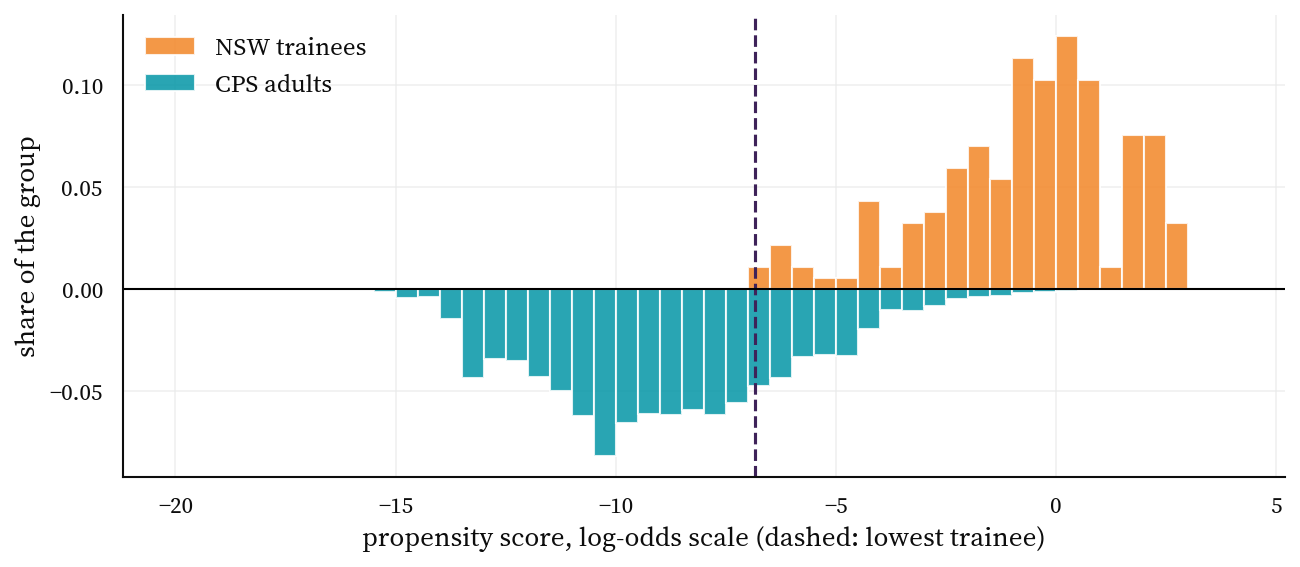

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
lo = np.log(obs.ps / (1 - obs.ps)).clip(-20, 5)
bins = np.linspace(-20, 4, 49)
for d, col, lab, sgn in [(1, T_COL, "NSW trainees", 1), (0, C_COL, "CPS adults", -1)]:
    h, _ = np.histogram(lo[obs.treat == d], bins)
    ax.bar(bins[:-1], sgn * h / h.sum(), width=bins[1] - bins[0], align="edge", color=col, alpha=0.85, label=lab)
ax.axvline(np.log(pmin / (1 - pmin)), color=PURPLE, ls="--")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("propensity score, log-odds scale (dashed: lowest trainee)"); ax.set_ylabel("share of the group")
ax.legend(); plt.show()

Most CPS adults have a pscore of almost zero: nobody like them joins the program, so they are useless as counterfactuals.

### 1.4 Matching estimators of the ATT

**Nearest neighbour** (with replacement, on the common support):
$$\widehat{\text{ATT}} = \frac{1}{N_1}\sum_{i:\,D_i=1}\Big(Y_i - \frac{1}{k}\sum_{j \in \mathcal{M}_k(i)} Y_j\Big)$$
where $\mathcal{M}_k(i)$ are the $k$ controls with the closest pscore.

In [8]:
from sklearn.neighbors import NearestNeighbors

def att_nn(d, k=1):
    t, c = d[d.treat == 1], d[d.treat == 0]
    nn = NearestNeighbors(n_neighbors=k).fit(c[["ps"]])
    _, idx = nn.kneighbors(t[["ps"]])
    y0 = c.re78.values[idx].mean(axis=1)
    return (t.re78.values - y0).mean(), len(np.unique(idx))

for k in (1, 5):
    att, n_used = att_nn(obs[obs.comsup], k)
    print(f"NN, k = {k}:  ATT = {att:8.1f}   ({n_used} distinct controls used)")

NN, k = 1:  ATT =    734.9   (110 distinct controls used)
NN, k = 5:  ATT =   1739.4   (366 distinct controls used)


**Kernel matching:** each treated unit is compared with a weighted average of *all* controls, with weights $w_{ij} \propto K\big((\hat p_j - \hat p_i)/h\big)$ (Gaussian kernel, bandwidth $h = 0.06$, the default of `attk`).
There is no analytical standard error, so we **bootstrap**: resample the data, re-estimate the pscore and the ATT, repeat, and take the standard deviation.

In [9]:
def att_kernel(d, h=0.06):
    t, c = d[d.treat == 1], d[d.treat == 0]
    K = stats.norm.pdf((c.ps.values[None, :] - t.ps.values[:, None]) / h)
    y0 = (K * c.re78.values[None, :]).sum(1) / K.sum(1)
    return (t.re78.values - y0).mean()

def full_kernel(d):
    d = d.copy()
    d["ps"] = smf.logit("treat ~ " + " + ".join(X2), d).fit(disp=0, method="newton", maxiter=200).predict(d)
    lo_, hi_ = d.ps[d.treat == 1].min(), d.ps[d.treat == 1].max()
    return att_kernel(d[d.ps.between(lo_, hi_)])

att_k = att_kernel(obs[obs.comsup])
rng = np.random.default_rng(669)
boot = []
for b in range(50):                                    # 50 replications, as in TA7.do
    idx = rng.integers(0, len(obs), len(obs))
    try:
        boot.append(full_kernel(obs.iloc[idx]))
    except Exception:                                  # rare non-convergence in a resample
        pass
print(f"Kernel ATT = {att_k:.1f}   bootstrap se = {np.std(boot, ddof=1):.1f}   ({len(boot)} replications)")

Kernel ATT = 1267.7   bootstrap se = 745.9   (50 replications)


### 1.5 Balance after matching
After NN matching ($k = 1$), the "control group" is the set of matched controls, weighted by how many times each one is used.

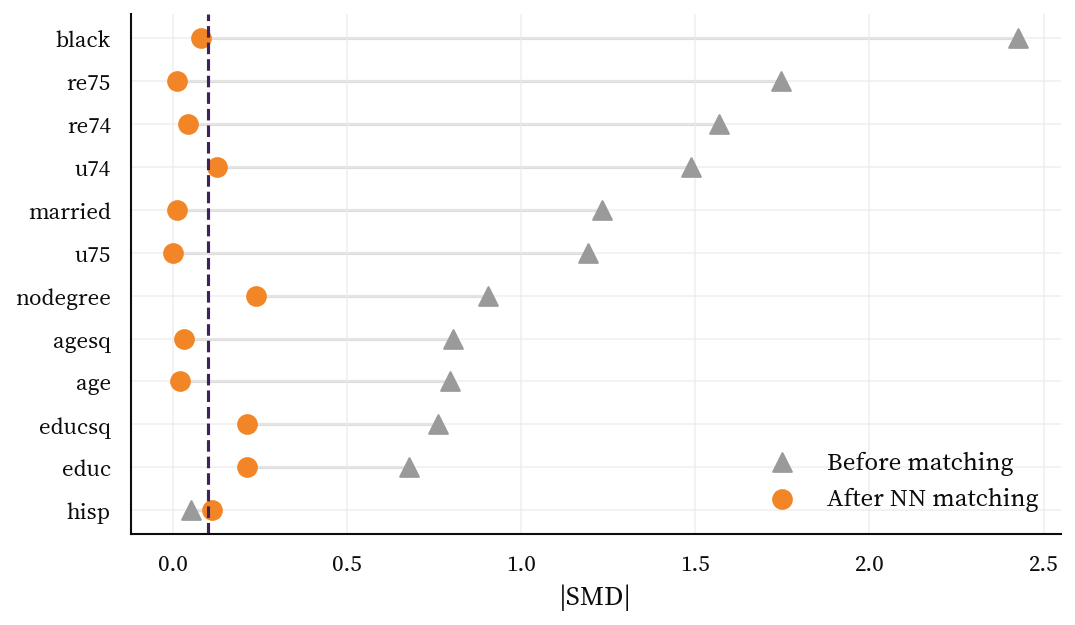

In [10]:
d = obs[obs.comsup]
t, c = d[d.treat == 1], d[d.treat == 0]
_, idx = NearestNeighbors(n_neighbors=1).fit(c[["ps"]]).kneighbors(t[["ps"]])
w0 = np.bincount(idx[:, 0], minlength=len(c)).astype(float)

love = pd.DataFrame({"before": [abs(smd(t_[v], c_[v])) for v in X],
                     "after": [abs(smd(t[v], c[v], w0 + 1e-12)) for v in X]}, index=X).sort_values("before")
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(love))
ax.scatter(love.before, y, marker="^", color=GRAY, s=80, label="Before matching")
ax.scatter(love.after, y, color=T_COL, s=80, label="After NN matching")
for k in range(len(love)):
    ax.plot([love.before.iloc[k], love.after.iloc[k]], [k, k], color="#DDD", zorder=0)
ax.axvline(0.1, color=PURPLE, ls="--"); ax.set_yticks(y); ax.set_yticklabels(love.index)
ax.set_xlabel("|SMD|"); ax.legend(); plt.show()

**Takeaway.** Experimental benchmark ≈ \$1,794; naive with CPS controls ≈ −\$8,498. Matching trainees to *comparable* CPS adults brings the estimate back to the experimental ballpark. It works here because we observe the key confounders (past earnings, unemployment). Matching cannot fix confounding by variables we do not observe.